# Chapter 4 · Forward Kinematics

**Companion notebook to *Mathematics for Robotics: A Beginner's Guide*** · ROSFORGE · rosforge.com

Read Chapter 4 of the book, then run each cell here to see the idea at work. Change the numbers and re-run: that is the fastest way to build intuition. Section numbers below match the book.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
np.set_printoptions(precision=3, suppress=True)
plt.rcParams["figure.figsize"] = (5, 5)
deg = np.pi / 180

def R2(a):
    c, s = np.cos(a), np.sin(a); return np.array([[c, -s], [s, c]])

def T2(R, p):
    # 3x3 homogeneous transform for 2D: rotation R (2x2) and position p
    T = np.eye(3); T[:2, :2] = R; T[:2, 2] = p; return T

def draw_frame2d(ax, T, scale=0.5, label=""):
    o = T[:2, 2]
    ax.annotate("", xy=o + scale * T[:2, 0], xytext=o, arrowprops=dict(arrowstyle="->", color="r", lw=2))
    ax.annotate("", xy=o + scale * T[:2, 1], xytext=o, arrowprops=dict(arrowstyle="->", color="g", lw=2))
    ax.text(*(o - 0.15), label)

def setup2d(ax, lim=3, title=""):
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); ax.set_aspect("equal"); ax.grid(alpha=.3); ax.set_title(title)

In [2]:
def inv_T(T):
    n = T.shape[0] - 1; R, p = T[:n, :n], T[:n, n]
    Ti = np.eye(n + 1); Ti[:n, :n] = R.T; Ti[:n, n] = -R.T @ p; return Ti

In [3]:
def Rz3(a): c, s = np.cos(a), np.sin(a); return np.array([[c, -s, 0], [s, c, 0], [0, 0, 1]])
def Rx3(a): c, s = np.cos(a), np.sin(a); return np.array([[1, 0, 0], [0, c, -s], [0, s, c]])

def T3(R, p):
    T = np.eye(4); T[:3, :3] = R; T[:3, 3] = p; return T
def rot_z(a): return T3(Rz3(a), [0, 0, 0])
def rot_x(a): return T3(Rx3(a), [0, 0, 0])
def trans(x, y, z): return T3(np.eye(3), [x, y, z])

T = T3(Rz3(0.7) @ Rx3(0.3), [1, 2, 3]); x = np.array([0.5, -1.0, 2.0])
print("T [x;1] = [Rx + p; 1]:", np.allclose(T @ np.append(x, 1), np.append(T[:3, :3] @ x + T[:3, 3], 1)))
print("T @ T^-1 = I:", np.allclose(T @ inv_T(T), np.eye(4)))

T [x;1] = [Rx + p; 1]: True
T @ T^-1 = I: True


## 4.1 and 4.2 The planar two-link arm
*Rotate by $q_1$, move $l_1$, rotate by $q_2$, move $l_2$*:
$T_{\text{hand}}=\operatorname{Rot}(q_1)\operatorname{Trans}(l_1,0)\operatorname{Rot}(q_2)\operatorname{Trans}(l_2,0)$, so $x=l_1\cos q_1+l_2\cos(q_1+q_2)$ and $y=l_1\sin q_1+l_2\sin(q_1+q_2)$.

hand position: [0.644 1.332]
closed form  : [np.float64(0.6444907187521269), np.float64(1.332153036795085)]
hand orientation angle: 99.99999999999999 deg  (= q1 + q2)


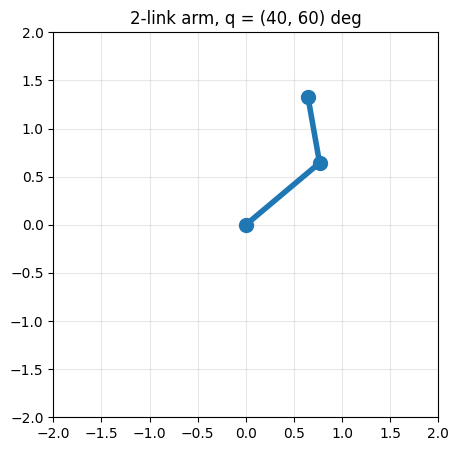

In [4]:
l1, l2 = 1.0, 0.7

def fk_2r(q, l1=l1, l2=l2):
    T = T2(R2(q[0]), [0, 0]) @ T2(np.eye(2), [l1, 0]) @ T2(R2(q[1]), [0, 0]) @ T2(np.eye(2), [l2, 0])
    return T

def arm_points(q, l1=l1, l2=l2):
    T1 = T2(R2(q[0]), [0, 0]) @ T2(np.eye(2), [l1, 0])
    T2_ = T1 @ T2(R2(q[1]), [0, 0]) @ T2(np.eye(2), [l2, 0])
    return np.array([[0, 0], T1[:2, 2], T2_[:2, 2]])

q = np.array([40 * deg, 60 * deg])
T = fk_2r(q)
print("hand position:", T[:2, 2])
print("closed form  :", [l1*np.cos(q[0]) + l2*np.cos(q.sum()), l1*np.sin(q[0]) + l2*np.sin(q.sum())])
print("hand orientation angle:", np.degrees(np.arctan2(T[1, 0], T[0, 0])), "deg  (= q1 + q2)")

fig, ax = plt.subplots(); pts = arm_points(q)
ax.plot(*pts.T, "o-", lw=4, ms=10); setup2d(ax, 2, "2-link arm, q = (40, 60) deg"); plt.show()

**Workspace by random sampling** (the Monte Carlo idea from the book): try many random joint angles, plot where the hand lands. No formula for the reachable region is needed.

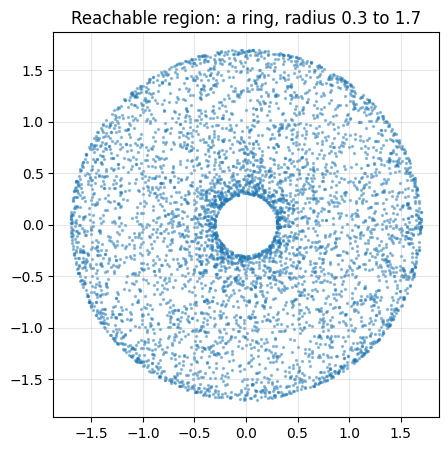

In [5]:
rng = np.random.default_rng(1)
qs = rng.uniform(-np.pi, np.pi, size=(5000, 2))
hand = np.array([fk_2r(q)[:2, 2] for q in qs])
plt.figure(figsize=(5, 5)); plt.scatter(*hand.T, s=2, alpha=.4); plt.gca().set_aspect("equal")
plt.title(f"Reachable region: a ring, radius {abs(l1-l2):.1f} to {l1+l2:.1f}"); plt.grid(alpha=.3); plt.show()

## 4.3 Denavit-Hartenberg parameters
Two conventions exist (standard and modified/Craig). Both describe the same arm and give the same pose, with different tables. Always check which one your course uses.

In [6]:
def std_dh(theta, d, a, alpha):
    return rot_z(theta) @ trans(0, 0, d) @ trans(a, 0, 0) @ rot_x(alpha)

def mod_dh(alpha_prev, a_prev, theta, d):
    return rot_x(alpha_prev) @ trans(a_prev, 0, 0) @ rot_z(theta) @ trans(0, 0, d)

q1, q2 = 40 * deg, 60 * deg
T_std = std_dh(q1, 0, l1, 0) @ std_dh(q2, 0, l2, 0)                                   # standard table rows: (theta, d, a, alpha)
T_mod = mod_dh(0, 0, q1, 0) @ mod_dh(0, l1, q2, 0) @ mod_dh(0, l2, 0, 0)               # modified table (last row = tool)
print("standard DH hand position:", T_std[:3, 3]); print("modified DH hand position:", T_mod[:3, 3])
print("same pose from both conventions:", np.allclose(T_std, T_mod), "  and equals the 2D result:", np.allclose(T_std[:2, 3], fk_2r([q1, q2])[:2, 2]))

standard DH hand position: [0.644 1.332 0.   ]
modified DH hand position: [0.644 1.332 0.   ]
same pose from both conventions: True   and equals the 2D result: True


## 4.4 A three-joint arm in space
Standard DH rows $(\theta,d,a,\alpha)$: $(q_1,d_1,0,90^\circ)$, $(q_2,0,l_2,0)$, $(q_3,0,l_3,0)$.

hand: [1.239 0.715 1.405] 
closed form: [1.239 0.715 1.405] 
match: True


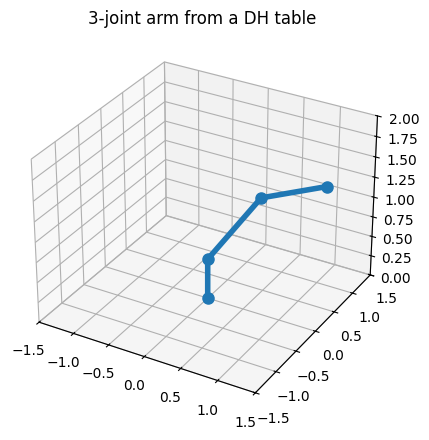

In [7]:
d1, l2_, l3_ = 0.5, 1.0, 0.8

def fk_3d(q):
    return std_dh(q[0], d1, 0, 90 * deg) @ std_dh(q[1], 0, l2_, 0) @ std_dh(q[2], 0, l3_, 0)

def joint_positions(q):
    A1 = std_dh(q[0], d1, 0, 90 * deg); A2 = A1 @ std_dh(q[1], 0, l2_, 0); A3 = A2 @ std_dh(q[2], 0, l3_, 0)
    return np.array([[0, 0, 0], A1[:3, 3], A2[:3, 3], A3[:3, 3]])

q = np.array([30 * deg, 50 * deg, -40 * deg]); T = fk_3d(q)
r = l2_ * np.cos(q[1]) + l3_ * np.cos(q[1] + q[2])
closed = [np.cos(q[0]) * r, np.sin(q[0]) * r, d1 + l2_ * np.sin(q[1]) + l3_ * np.sin(q[1] + q[2])]
print("hand:", T[:3, 3], "\nclosed form:", np.array(closed), "\nmatch:", np.allclose(T[:3, 3], closed))

P = joint_positions(q); ax = plt.figure(figsize=(5, 5)).add_subplot(projection="3d")
ax.plot(*P.T, "o-", lw=4, ms=8); ax.set_xlim(-1.5, 1.5); ax.set_ylim(-1.5, 1.5); ax.set_zlim(0, 2); ax.set_title("3-joint arm from a DH table"); plt.show()

---
## Exercises

> **Exercise 4.1**
>
> A planar arm has $l_1=2$, $l_2=1$ and $q=(0^\circ,90^\circ)$. Where is the hand?

In [8]:
# Your work here (try the exercise before looking at the solution cell below)

**Solution 4.1** *(this is the book's Appendix B, checked in code)*

In [9]:
p = fk_2r([0, 90*deg], 2.0, 1.0)[:2, 2]; print(p.round(6)); assert np.allclose(p, [2, 1])

[2. 1.]


> **Exercise 4.2**
>
> What is the workspace of a planar two-link arm with $l_1=3$ and $l_2=1$?

In [10]:
# Your work here (try the exercise before looking at the solution cell below)

**Solution 4.2** *(this is the book's Appendix B, checked in code)*

In [11]:
rng = np.random.default_rng(0); r = np.array([np.linalg.norm(fk_2r(q, 3.0, 1.0)[:2, 2]) for q in rng.uniform(-np.pi, np.pi, size=(20000, 2))])
print("distances from the base range over", r.min().round(3), "to", r.max().round(3)); assert abs(r.min() - 2) < 0.01 and abs(r.max() - 4) < 0.01
print("a ring with inner radius |3-1| = 2 and outer radius 3+1 = 4")

distances from the base range over 2.0 to 4.0
a ring with inner radius |3-1| = 2 and outer radius 3+1 = 4


> **Exercise 4.3**
>
> For $l_1=l_2=1$ and $q=(30^\circ,60^\circ)$, find the hand position and orientation angle.

In [12]:
# Your work here (try the exercise before looking at the solution cell below)

**Solution 4.3** *(this is the book's Appendix B, checked in code)*

In [13]:
T = fk_2r([30*deg, 60*deg], 1.0, 1.0); print(T[:2, 2].round(4), np.degrees(np.arctan2(T[1, 0], T[0, 0])).round(4))
assert np.allclose(T[:2, 2], [0.866, 1.5], atol=1e-3) and np.isclose(np.degrees(np.arctan2(T[1, 0], T[0, 0])), 90)

[0.866 1.5  ] 90.0


> **Exercise 4.4**
>
> Write the standard-DH transform for the row $(\theta,d,a,\alpha)=(90^\circ,0,1,0)$ and find the position of the new frame's origin.

In [14]:
# Your work here (try the exercise before looking at the solution cell below)

**Solution 4.4** *(this is the book's Appendix B, checked in code)*

In [15]:
A = std_dh(90*deg, 0, 1.0, 0); print(A.round(6)); assert np.allclose(A[:3, 3], [0, 1, 0])
print("Rot_z(90) Trans_x(1) puts the new origin at (0, 1, 0)")

[[ 0. -1.  0.  0.]
 [ 1.  0.  0.  1.]
 [ 0.  0.  1.  0.]
 [ 0.  0.  0.  1.]]
Rot_z(90) Trans_x(1) puts the new origin at (0, 1, 0)


---
**Next:** `05_Jacobians.ipynb` (Chapter 5)

*Mathematics for Robotics: A Beginner's Guide* · ROSFORGE · rosforge.com